In [33]:

import pandas as pd 
import numpy as np
from scipy import stats
from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split , GridSearchCV, cross_val_score
from sklearn.compose import make_column_transformer , ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder , OrdinalEncoder

from sklearn.linear_model import LinearRegression ,Ridge, Lasso , ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.kernel_ridge import KernelRidge


In [50]:
df_train = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

In [35]:
def plot_numeric_vs_saleprice(df):
    """
    Plots scatter plots of all numerical features against the target variable 'SalePrice'.

    This function iterates through all numerical columns in the given DataFrame (excluding 
    object-type columns and the 'SalePrice' column itself), and creates a scatter plot 
    between each feature and 'SalePrice'. It is useful for visually analyzing the 
    relationships and possible correlations between features and the target variable.

    Parameters
    ----------
    df : pandas.DataFrame
        A dataset that includes numerical features and the target column 'SalePrice'.

    Returns
    -------
    None
        The function does not return anything. It displays the plots using matplotlib.
    """
    numeric_cols = df.dtypes[df.dtypes != 'object'].index
    numeric_cols = [col for col in numeric_cols if col != 'SalePrice']  # exclude target

    for col in numeric_cols:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(x=col, y='SalePrice', data=df)
        plt.title(f'{col} vs SalePrice')
        plt.xlabel(col)
        plt.ylabel('SalePrice')
        plt.tight_layout()
        plt.show()


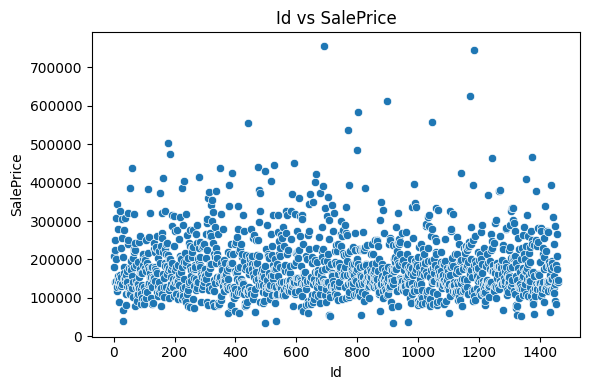

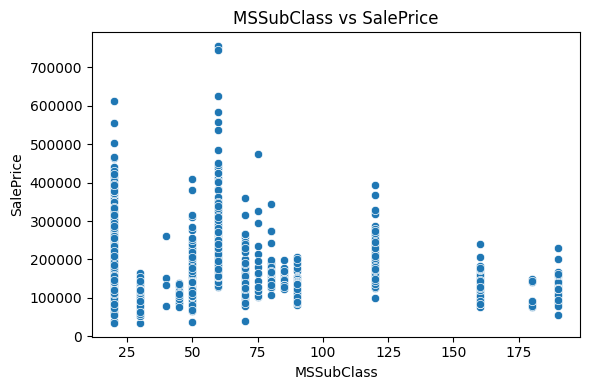

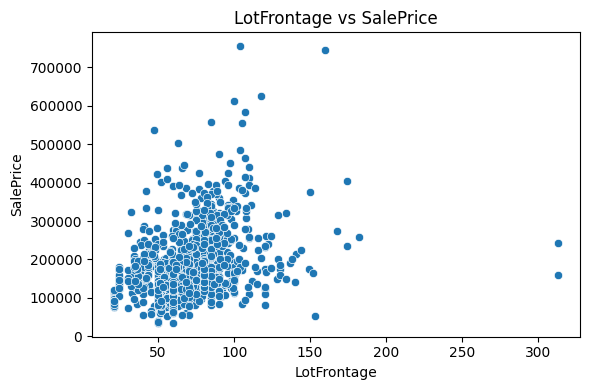

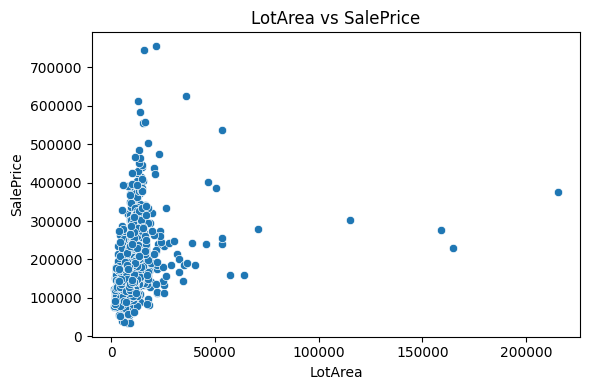

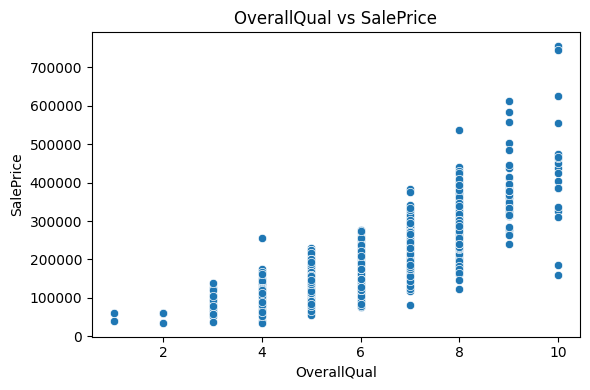

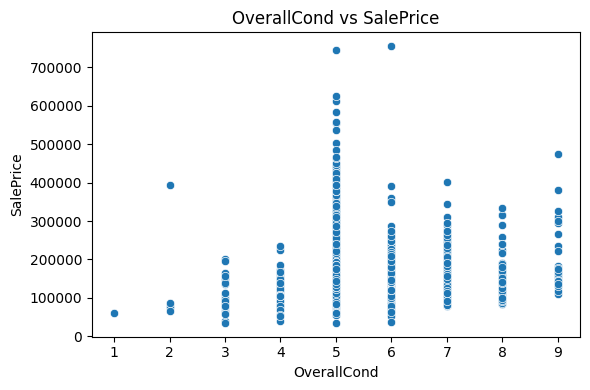

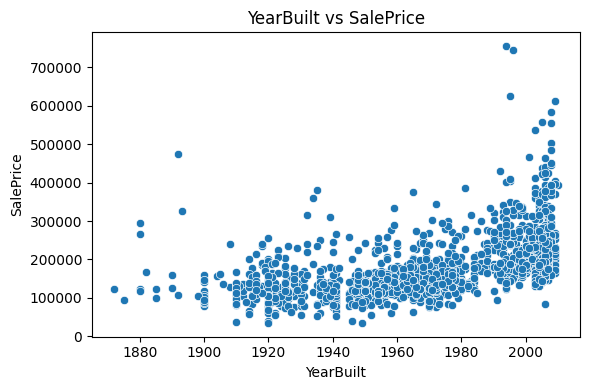

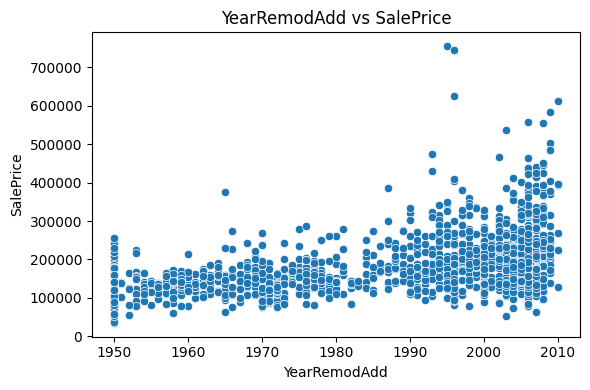

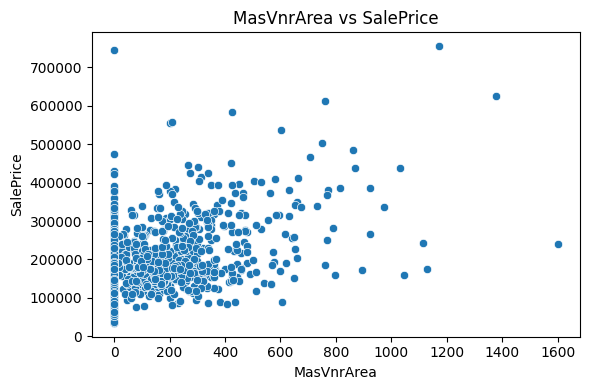

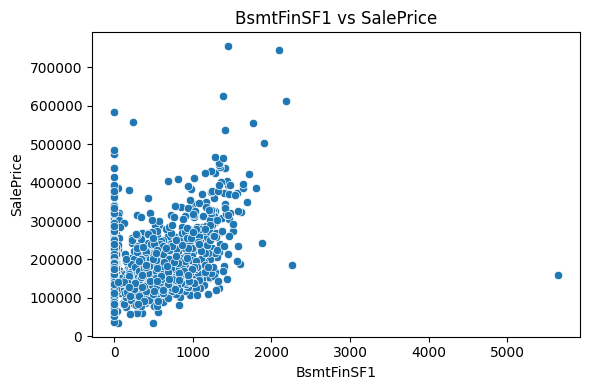

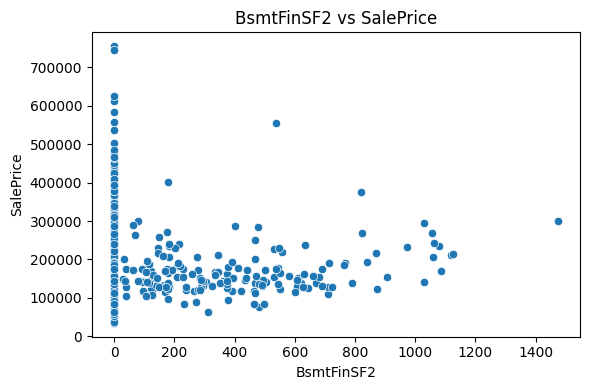

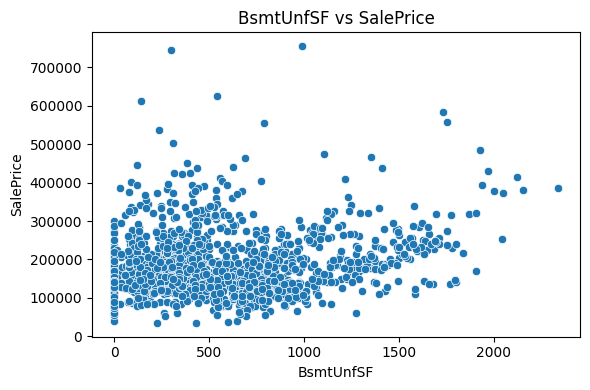

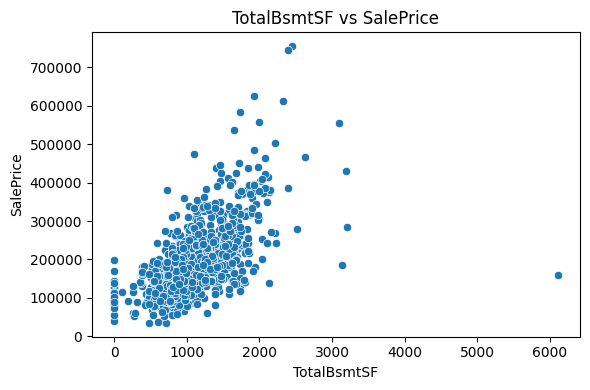

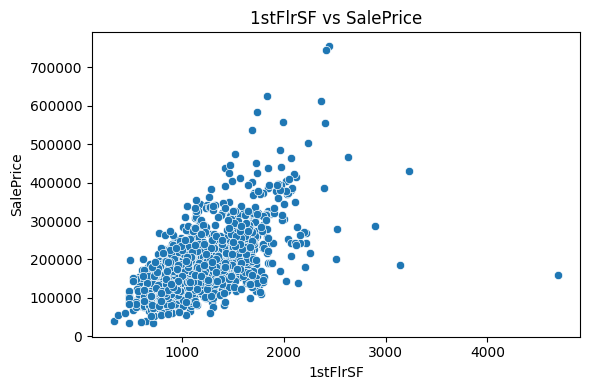

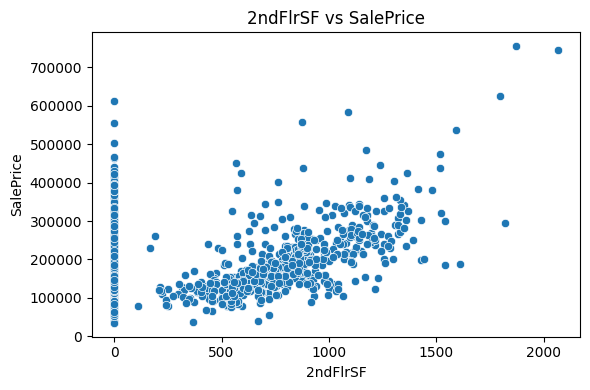

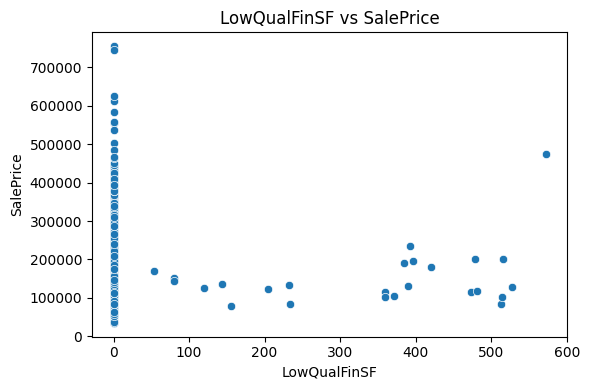

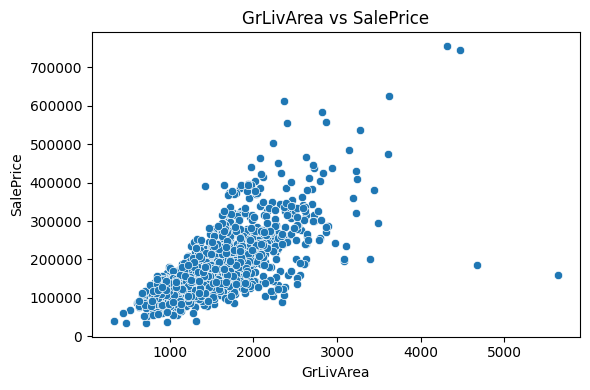

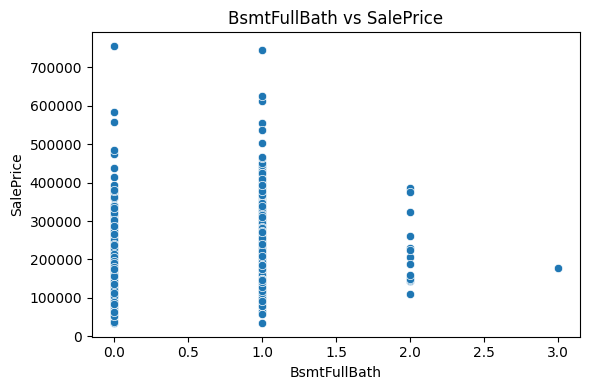

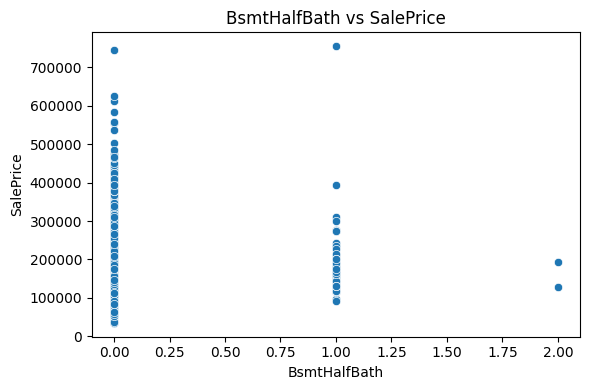

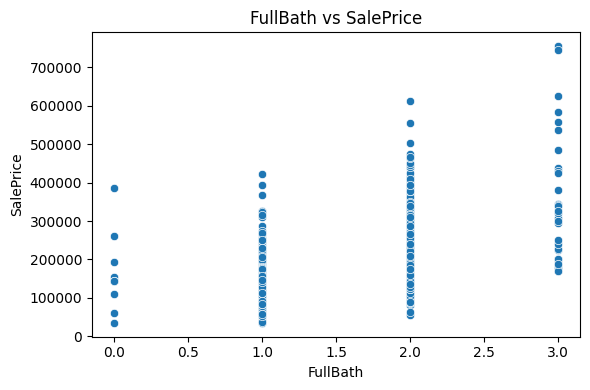

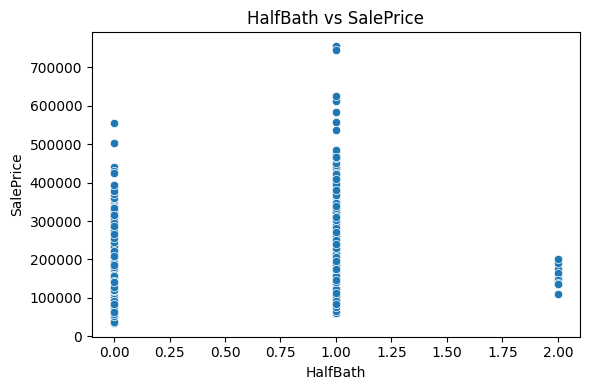

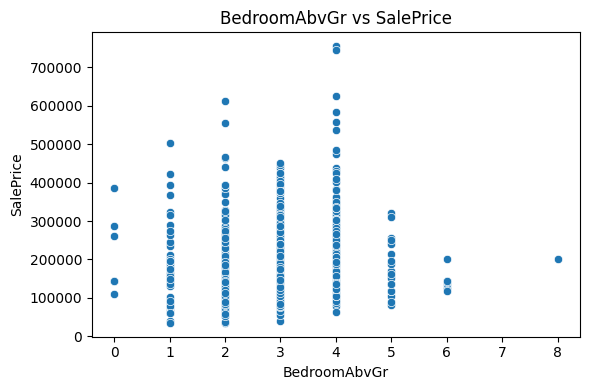

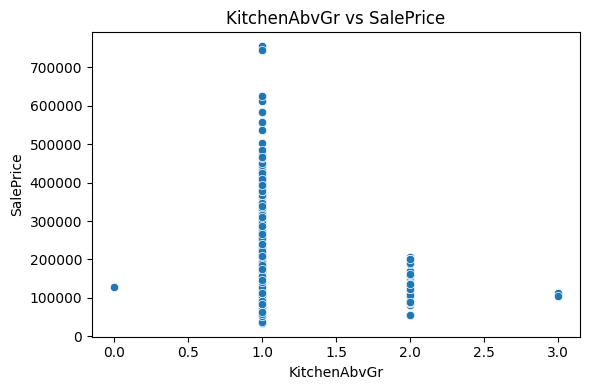

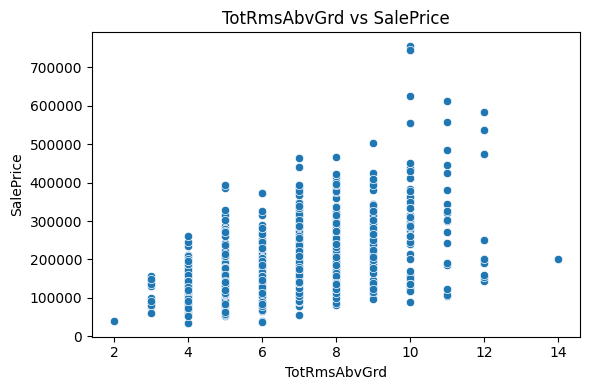

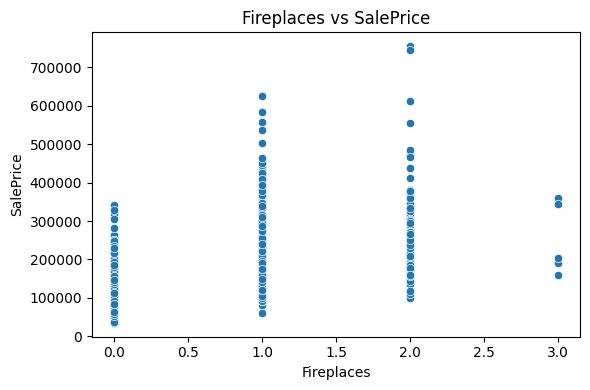

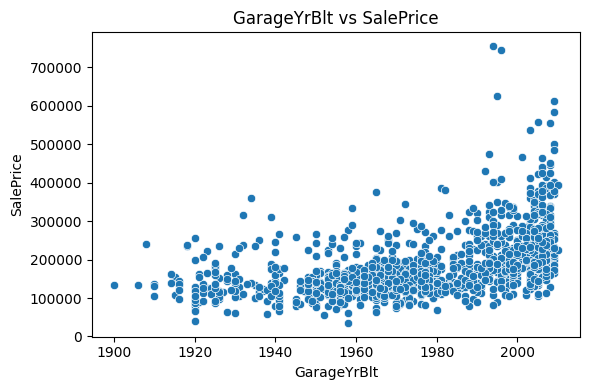

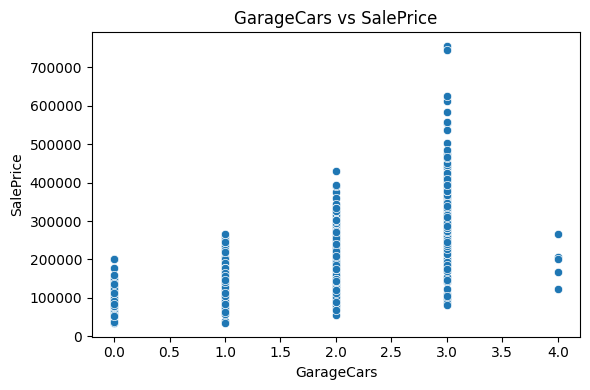

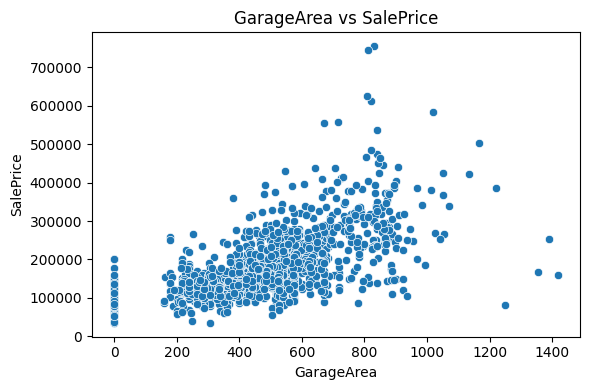

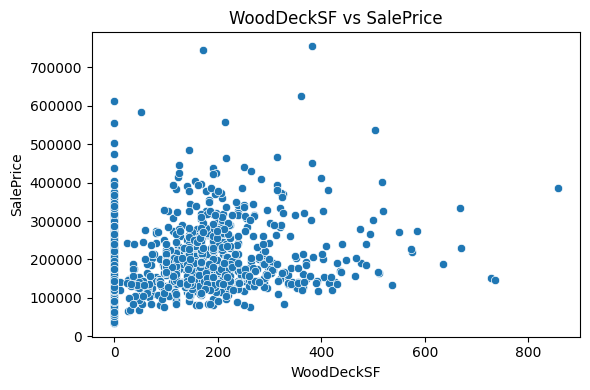

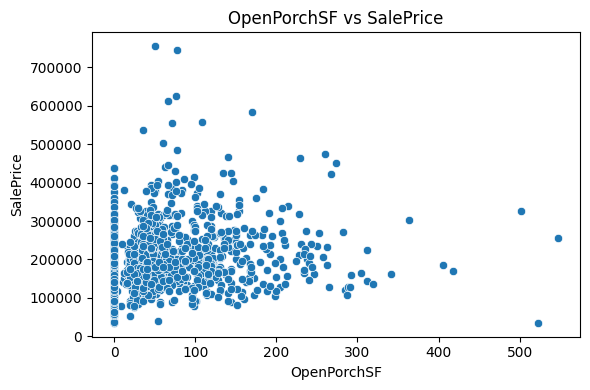

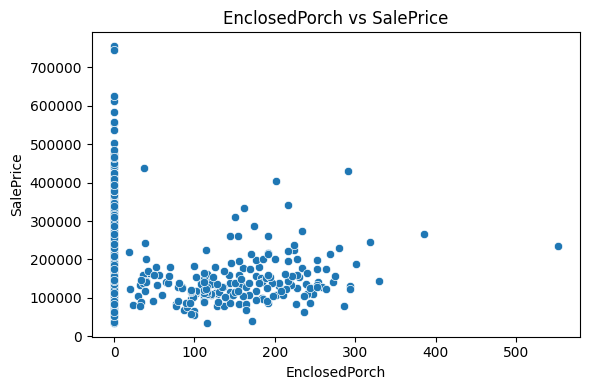

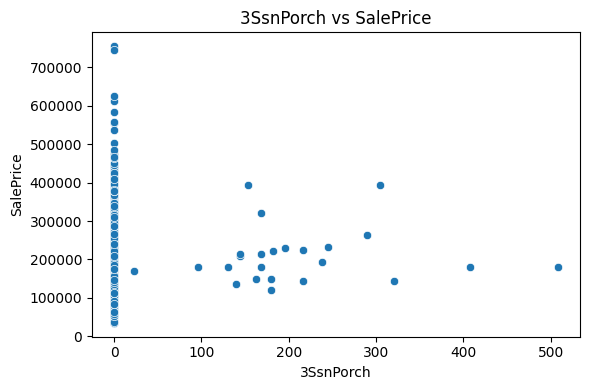

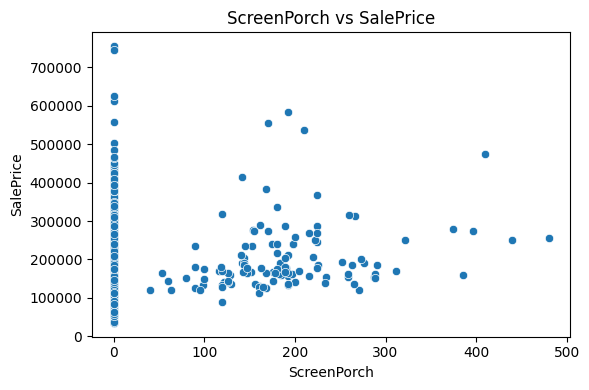

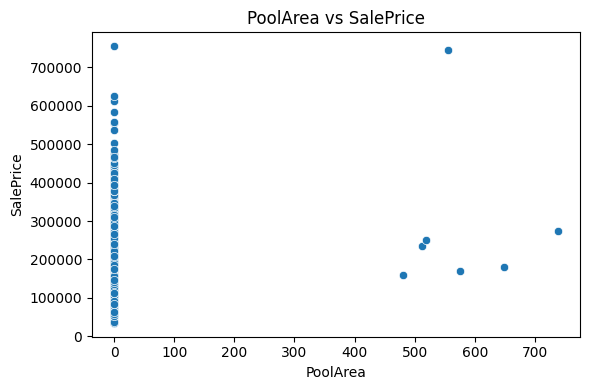

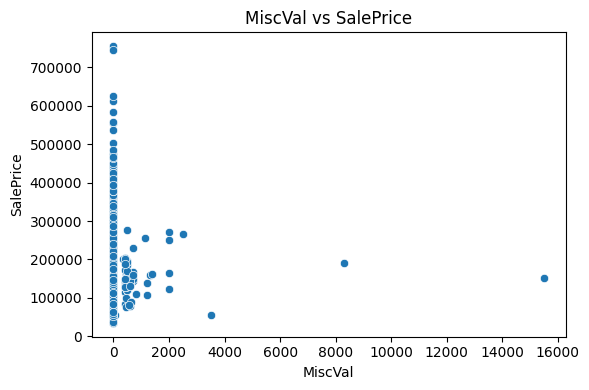

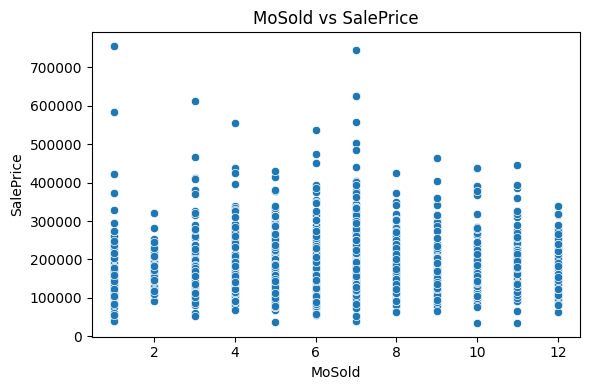

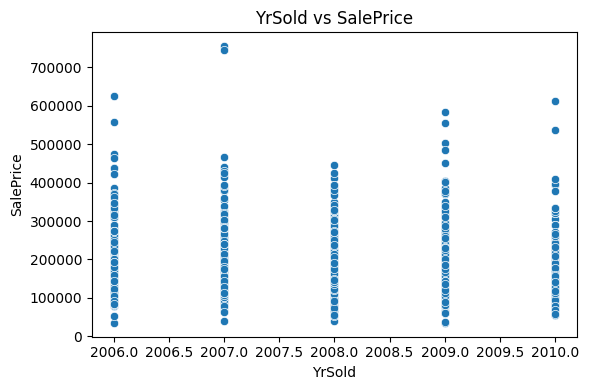

In [36]:
plot_numeric_vs_saleprice(df_train.select_dtypes(exclude=['object']))

In [37]:
df_train.query('OverallCond > 2 & SalePrice > 700000')
#drop 379 , 1183

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [38]:
df_train.query('YearBuilt < 1990 & SalePrice >400000')
#Drop 186

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
185,186,75,RM,90.0,22950,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,6,2006,WD,Normal,475000


In [39]:
df_train.query('YearBuilt> 1980 & SalePrice > 600000')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
691,692,60,RL,104.0,21535,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,755000
898,899,20,RL,100.0,12919,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2010,New,Partial,611657
1169,1170,60,RL,118.0,35760,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,625000
1182,1183,60,RL,160.0,15623,Pave,NaN,IR1,Lvl,AllPub,...,555,Ex,MnPrv,NaN,0,7,2007,WD,Abnorml,745000


In [40]:
df_train.query('YearRemodAdd < 1970 & SalePrice > 300000')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
313,314,20,RL,150.0,215245,Pave,NaN,IR3,Low,AllPub,...,0,NaN,NaN,NaN,0,6,2009,WD,Normal,375000


In [41]:
df_train.query('MasVnrArea > 1500')
#drop 298

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
297,298,60,FV,66.0,7399,Pave,Pave,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2007,WD,Normal,239000


In [42]:
df_train.query('BsmtFinSF2 > 400 & SalePrice > 500000')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
440,441,20,RL,105.0,15431,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2009,WD,Normal,555000


In [43]:
values = [598, 955, 935, 1299, 250, 314, 336, 707, 379, 1183, 692, 186, 441, 186, 524, 739, 598, 955, 636, 1062, 1191, 496, 198, 1338]

df_train = df_train[~df_train.Id.isin(values)]


In [44]:
pd.DataFrame(df_train.isnull().sum().sort_values(ascending = False)).head(20)

,0
PoolQC,1435
MiscFeature,1388
Alley,1350
Fence,1162
MasVnrType,861
FireplaceQu,684
LotFrontage,255
GarageYrBlt,76
GarageCond,76
GarageType,76


In [45]:

df_train['MiscFeature'].unique()

array([nan, 'Shed', 'Gar2', 'Othr', 'TenC'], dtype=object)

In [46]:
df_train['Alley'].unique()

array([nan, 'Grvl', 'Pave'], dtype=object)

In [51]:
df_train['Alley'] = df_train['Alley'].fillna('No')
df_test['Alley'] = df_test['Alley'].fillna('No')


In [52]:
df_train['Alley'].isnull().sum()

np.int64(0)

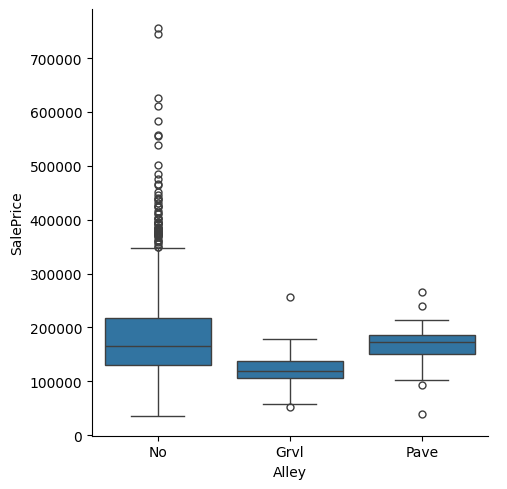

In [54]:
sns.catplot(data = df_train, x = 'Alley', y = 'SalePrice',kind = 'box')

In [58]:
df_train.query('Alley == "Pave"').count()

Id               41
MSSubClass       41
MSZoning         41
LotFrontage      39
LotArea          41
                 ..
MoSold           41
YrSold           41
SaleType         41
SaleCondition    41
SalePrice        41
Length: 81, dtype: int64

In [59]:
df_train['Fence'].unique()

array([nan, 'MnPrv', 'GdWo', 'GdPrv', 'MnWw'], dtype=object)

In [60]:
df_train['Fence'] = df_train['Fence'].fillna('No')
df_test['Fence'] = df_test['Fence'].fillna('No')

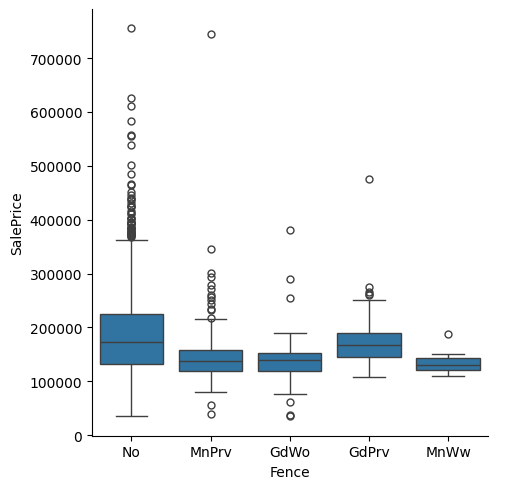

In [61]:
sns.catplot(df_train , x = 'Fence', y = 'SalePrice',kind = 'box')

In [67]:
df_train['MasVnrArea'].isnull().sum()
df_test['MasvnrArea'] = df_test['MasVnrArea'].fillna('0')
df_train['MasvnrArea'] = df_test['MasVnrArea'].fillna('0')


In [69]:
df_train['FireplaceQu'].unique()

array([nan, 'TA', 'Gd', 'Fa', 'Ex', 'Po'], dtype=object)

In [70]:
df_train['FireplaceQu'] = df_train['FireplaceQu'].fillna('No')
df_test['FireplaceQu'] = df_test['FireplaceQu'].fillna('No')

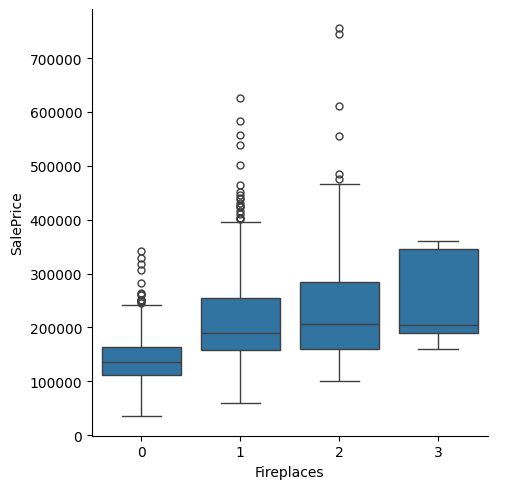

In [74]:
sns.catplot(df_train , x = 'Fireplaces', y = 'SalePrice',kind = 'box')

In [75]:
df_train['LotFrontage'].isnull().sum()

df_train['LotFrontage'] = df_train['LotFrontage'].fillna(0)
df_test['LotFrontage'] = df_test['LotFrontage'].fillna(0)

In [83]:
df_train.isnull().sum()

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
                ..
YrSold           0
SaleType         0
SaleCondition    0
SalePrice        0
MasvnrArea       1
Length: 82, dtype: int64

In [84]:
df_train['GarageYrBlt'].corr(df_train['YearBuilt'])

np.float64(0.8256674841743427)

In [86]:
df_train['GarageCond'].unique()
df_train['GarageCond'] = df_train['GarageCond'].fillna('No')
df_test['GarageCond'] = df_test['GarageCond'].fillna('No')


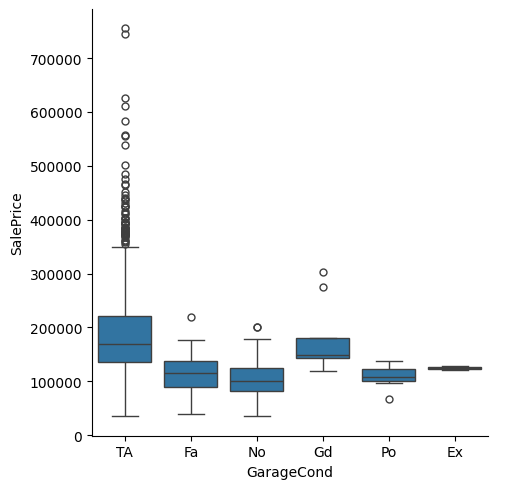

In [87]:
sns.catplot(df_train, x = 'GarageCond', y = 'SalePrice',kind = 'box')

In [89]:
df_train['GarageType'].unique()
df_train['GarageType'] = df_train['GarageType'].fillna('No')
df_test['GarageType'] = df_test['GarageType'].fillna('No')

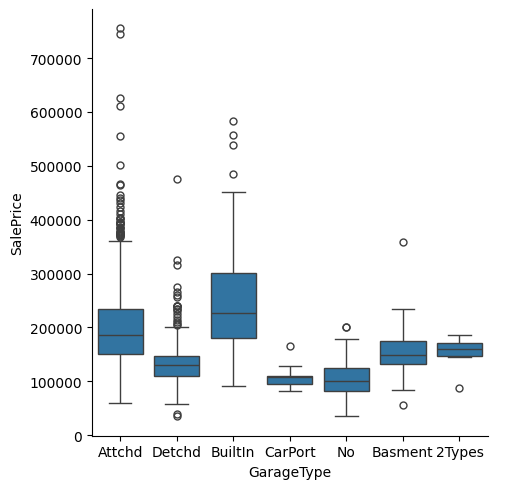

In [90]:
sns.catplot(df_train, x = 'GarageType', y = 'SalePrice',kind = 'box')

In [92]:
df_train['GarageFinish'].unique()
df_train['GarageFinish'] = df_train['GarageFinish'].fillna('No')
df_test['GarageFinish'] = df_test['GarageFinish'].fillna('No')


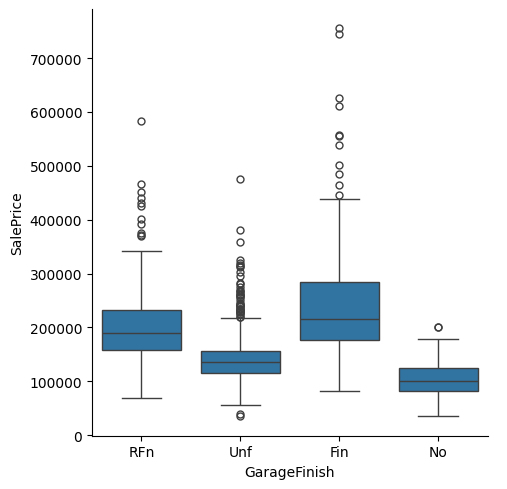

In [93]:
sns.catplot(df_train, x = 'GarageFinish', y = 'SalePrice',kind = 'box')

In [95]:
#df_train['BsmtFinType2'] = df_train['BsmtFinType2'].fillna('Unf')
#df_test['BsmtFinType2'] = df_test['BsmtFinType2'].fillna('Unf')

df_train['BsmtFinType2'].unique()

array(['Unf', 'BLQ', 'ALQ', 'Rec', 'LwQ', 'GLQ'], dtype=object)

In [98]:
numeric_cols = df_train.dtypes[df_train.dtypes != 'object'].index
for col in numeric_cols:
    print(f'{col}')


Id
MSSubClass
LotFrontage
LotArea
OverallQual
OverallCond
YearBuilt
YearRemodAdd
MasVnrArea
BsmtFinSF1
BsmtFinSF2
BsmtUnfSF
TotalBsmtSF
1stFlrSF
2ndFlrSF
LowQualFinSF
GrLivArea
BsmtFullBath
BsmtHalfBath
FullBath
HalfBath
BedroomAbvGr
KitchenAbvGr
TotRmsAbvGrd
Fireplaces
GarageYrBlt
GarageCars
GarageArea
WoodDeckSF
OpenPorchSF
EnclosedPorch
3SsnPorch
ScreenPorch
PoolArea
MiscVal
MoSold
YrSold
SalePrice


In [100]:
#df_train['BsmtExposure'].unique()
df_train['BsmtExposure'] = df_train['BsmtExposure'].fillna('No')
df_test['BsmtExposure'] = df_test['BsmtExposure'].fillna('No')

In [103]:
#df_train['BsmtQual'].unique()
df_train['BsmtQual'] = df_train['BsmtQual'].fillna('No')
df_test['BsmtQual'] = df_test['BsmtQual'].fillna('No')

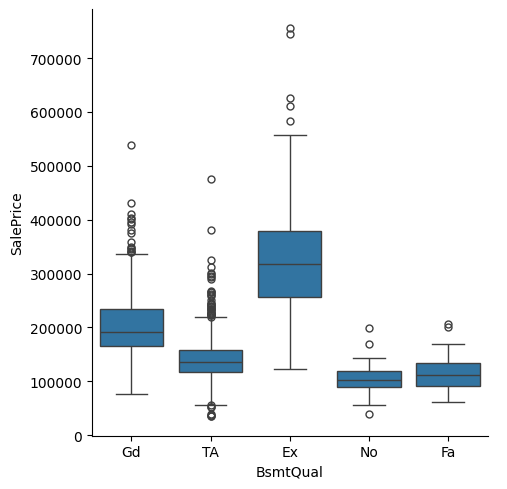

In [104]:
sns.catplot(df_train , x = 'BsmtQual', y = 'SalePrice',kind = 'box')

In [112]:
#df_train['BsmtFinType1'].unique()
df_train['BsmtFinType1'] = df_train['BsmtFinType1'].fillna('Unf')
df_test['BsmtFinType1'] = df_test['BsmtFinType1'].fillna('Unf')


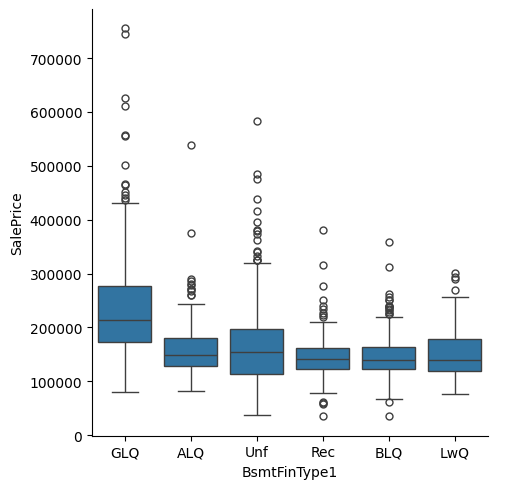

In [113]:
sns.catplot(df_train, x = 'BsmtFinType1', y = 'SalePrice',kind = 'box')

In [116]:
df_train['MasvnrArea'] = df_train['MasVnrArea'].fillna(0)
df_test['MasvnrArea'] = df_test['MasVnrArea'].fillna(0)
df_train['Electrical'] = df_train['Electrical'].fillna('SBrkr')
df_test['Electrical'] = df_test['Electrical'].fillna('SBrkr')


In [117]:
df_train = df_train.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'GarageYrBlt', 'GarageCond', 'BsmtFinType2'])
df_test = df_test.drop(columns=['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'GarageYrBlt', 'GarageCond', 'BsmtFinType2'])

## Lots of empty

# Feature Engineering


In [118]:
df_train['house_age'] = df_train['YrSold'] - df_train['YearBuilt']

In [131]:
df_train['house_remodel_age'] = df_train['YrSold'] - df_train['YearRemodAdd']
df_train['totalsf'] = df_train['1stFlrSF'] + df_train['2ndFlrSF'] + df_train['BsmtFinSF1']+ df_train['BsmtFinSF2']
df_train['totalarea'] = df_train['GrLivArea'] + df_train['TotalBsmtSF']
df_train['totalbaths'] = df_train['BsmtFullBath'] + df_train['FullBath'] + 0.5*(df_train['BsmtHalfBath'] + df_train['HalfBath'])
df_train['totalporchsf'] = df_train['OpenPorchSF'] + df_train['3SsnPorch'] + df_train['EnclosedPorch'] + df_train['ScreenPorch'] + df_train['WoodDeckSF']

df_test['house_remodel_age'] = df_test['YrSold'] - df_test['YearRemodAdd']
df_test['totalsf'] = df_test['1stFlrSF'] + df_test['2ndFlrSF'] + df_test['BsmtFinSF1'] + df_test['BsmtFinSF2']
df_test['totalarea'] = df_test['GrLivArea'] + df_test['TotalBsmtSF']
df_test['totalbaths'] = df_test['BsmtFullBath'] + df_test['FullBath'] + 0.5 * (df_test['BsmtHalfBath'] + df_test['HalfBath'])
df_test['totalporchsf'] = df_test['OpenPorchSF'] + df_test['3SsnPorch'] + df_test['EnclosedPorch'] + df_test['ScreenPorch'] + df_test['WoodDeckSF']




In [132]:
df_train = df_train.drop(columns=['Id','YrSold', 'YearBuilt', 'YearRemodAdd', '1stFlrSF', '2ndFlrSF', 'BsmtFinSF1', 'BsmtFinSF2', 'GrLivArea', 'TotalBsmtSF','BsmtFullBath', 'FullBath', 'BsmtHalfBath', 'HalfBath', 'OpenPorchSF', '3SsnPorch', 'EnclosedPorch', 'ScreenPorch','WoodDeckSF'])

df_test = df_test.drop(columns= ['Id','YrSold', 'YearBuilt', 'YearRemodAdd', '1stFlrSF', '2ndFlrSF', 'BsmtFinSF1', 'BsmtFinSF2', 'GrLivArea', 'TotalBsmtSF','BsmtFullBath', 'FullBath', 'BsmtHalfBath', 'HalfBath', 'OpenPorchSF', '3SsnPorch', 'EnclosedPorch', 'ScreenPorch','WoodDeckSF'])

<Axes: >

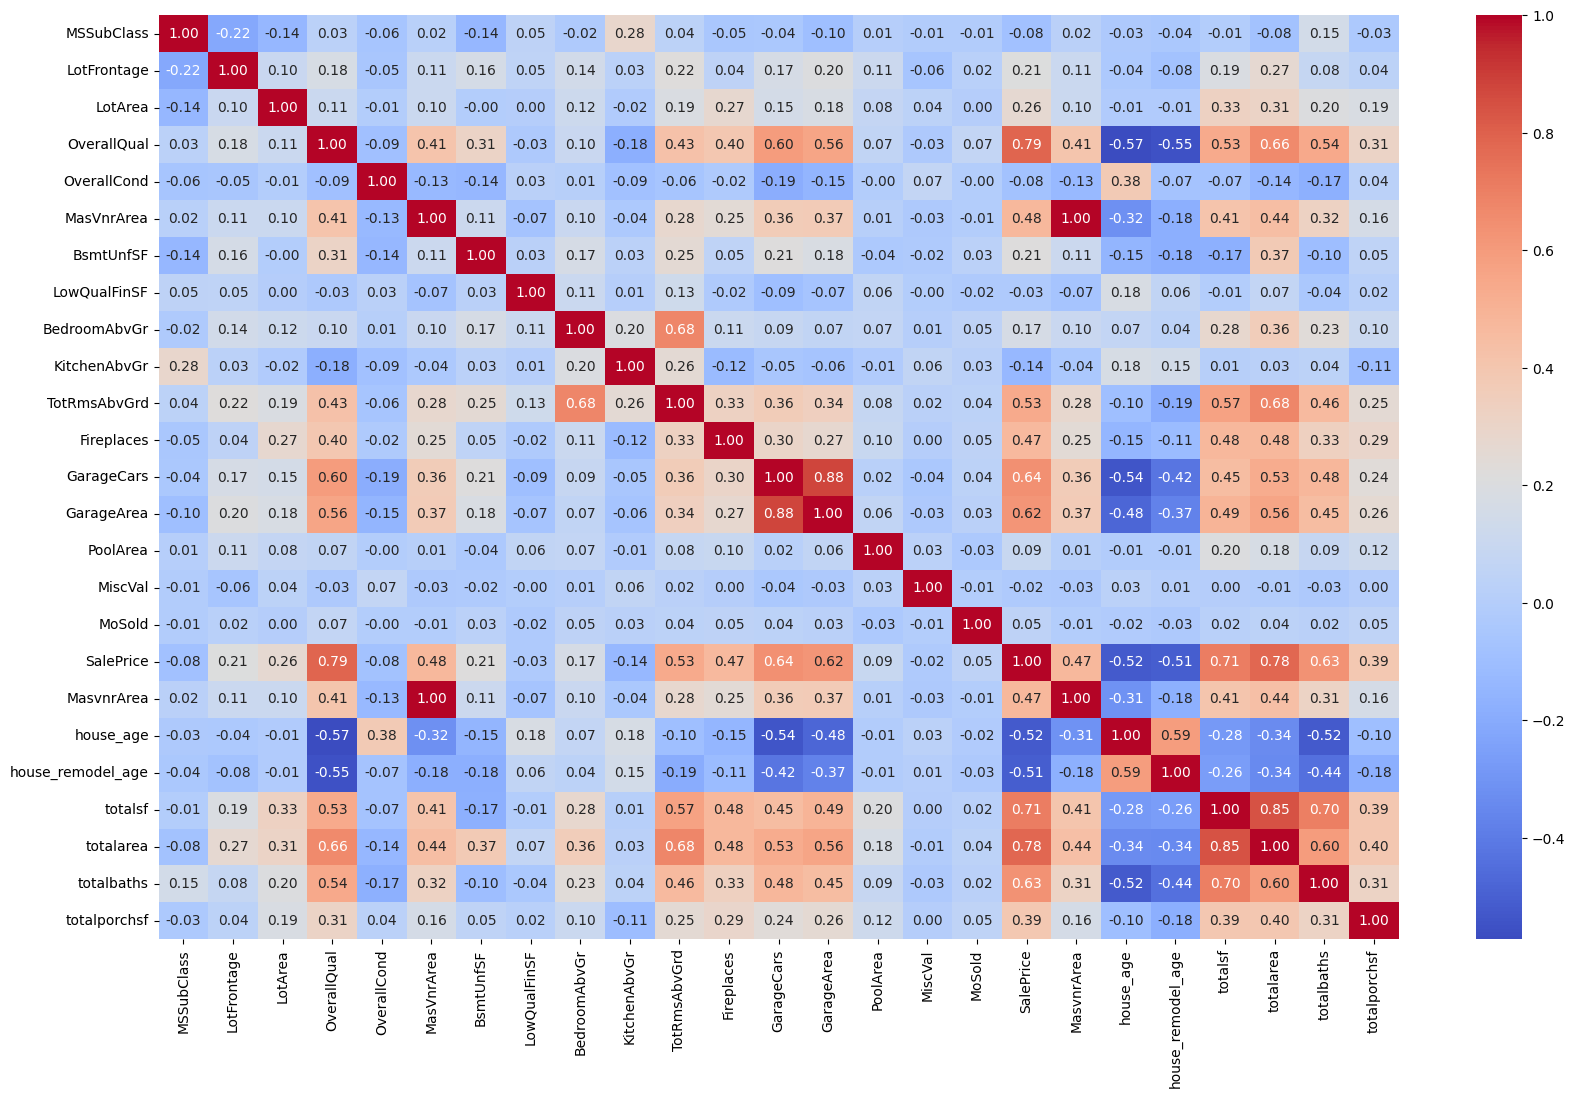

In [135]:
correlation_matrix = df_train.corr(numeric_only=True)
plt.figure(figsize=(20,12))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

In [136]:
df_train.drop(columns=['GarageArea'])
df_test.drop(columns=['GarageArea'])

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,...,MiscVal,MoSold,SaleType,SaleCondition,MasvnrArea,house_remodel_age,totalsf,totalarea,totalbaths,totalporchsf
0,20,RH,80.0,11622,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,6,WD,Normal,0.0,49,1508.0,1778.0,1.0,260
1,20,RL,81.0,14267,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,12500,6,WD,Normal,108.0,52,2252.0,2658.0,1.5,429
2,60,RL,74.0,13830,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,3,WD,Normal,0.0,12,2420.0,2557.0,2.5,246
3,60,RL,78.0,9978,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,6,WD,Normal,20.0,12,2206.0,2530.0,2.5,396
4,120,RL,43.0,5005,Pave,IR1,HLS,AllPub,Inside,Gtl,...,0,1,WD,Normal,0.0,18,1543.0,2560.0,2.0,226
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1454,160,RM,21.0,1936,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,6,WD,Normal,0.0,36,1092.0,1638.0,1.5,0
1455,160,RM,21.0,1894,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,4,WD,Abnorml,0.0,36,1344.0,1638.0,1.5,24
1456,20,RL,160.0,20000,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,9,WD,Abnorml,0.0,10,2448.0,2448.0,2.0,474
1457,85,RL,62.0,10441,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,700,7,WD,Normal,0.0,14,1307.0,1882.0,1.5,112


<Axes: xlabel='SalePrice', ylabel='Count'>

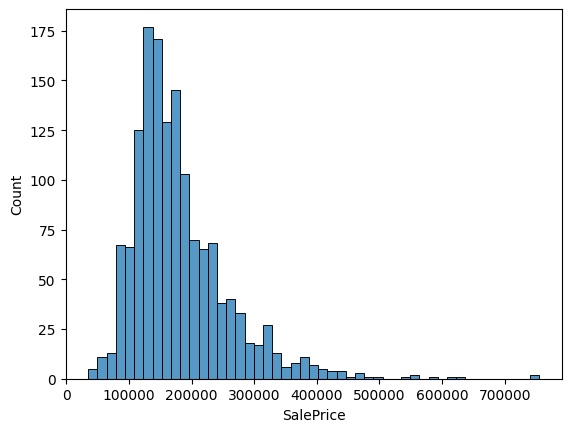

In [141]:
sns.histplot(df_train , x = df_train['SalePrice'])

In [142]:
df_train['SalePrice'] = np.log1p(df_train['SalePrice'])

<Axes: xlabel='SalePrice', ylabel='Count'>

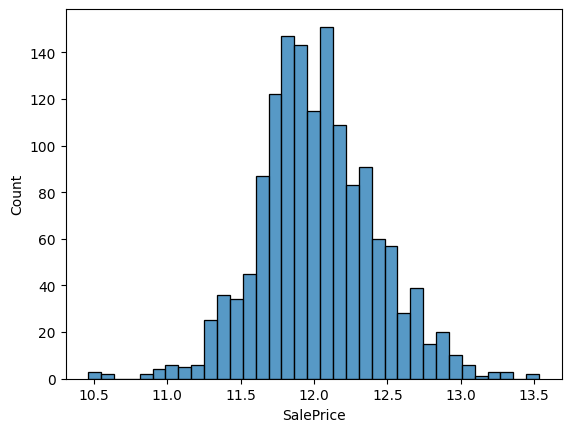

In [143]:
sns.histplot(df_train , x = df_train['SalePrice'])


In [ ]:
df_train